# Лабораторная работа 2. Спектральная теория случайных матриц
### От иллюзии шума к диагностике нейросетей

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse.linalg import svds

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
random_gen = np.random.default_rng(42)

## Задание 1. Спектр чистого шума: закон Марченко–Пастура
### 1.1. Функции

In [2]:
def noise_eigenvalues(p, n, sigma2=1.0):
    X = random_gen.normal(loc=0.0, scale=np.sqrt(sigma2), size=(p, n))
    sample_cov = X @ X.T / n
    return np.linalg.eigvalsh(sample_cov)


def mp_bounds(gamma, sigma2=1.0):
    lam_minus = sigma2 * (1 - np.sqrt(gamma)) ** 2
    lam_plus = sigma2 * (1 + np.sqrt(gamma)) ** 2
    return lam_minus, lam_plus


def mp_density(lam, gamma, sigma2=1.0):
    lam_minus, lam_plus = mp_bounds(gamma, sigma2)
    lam = np.asarray(lam, dtype=float)
    density = np.zeros_like(lam)
    inside = (lam > lam_minus) & (lam < lam_plus)
    x = lam[inside]
    density[inside] = np.sqrt((lam_plus - x) * (x - lam_minus)) / (2 * np.pi * sigma2 * gamma * x)
    return density

### 1.2. Эксперимент в двух режимах ($n = 1000$)

B (дефект ранга): нулевых собственных чисел 1000 (ожидалось p - n = 1000); самый большой |ноль| = 3.4e-15; отрицательных среди них: 494


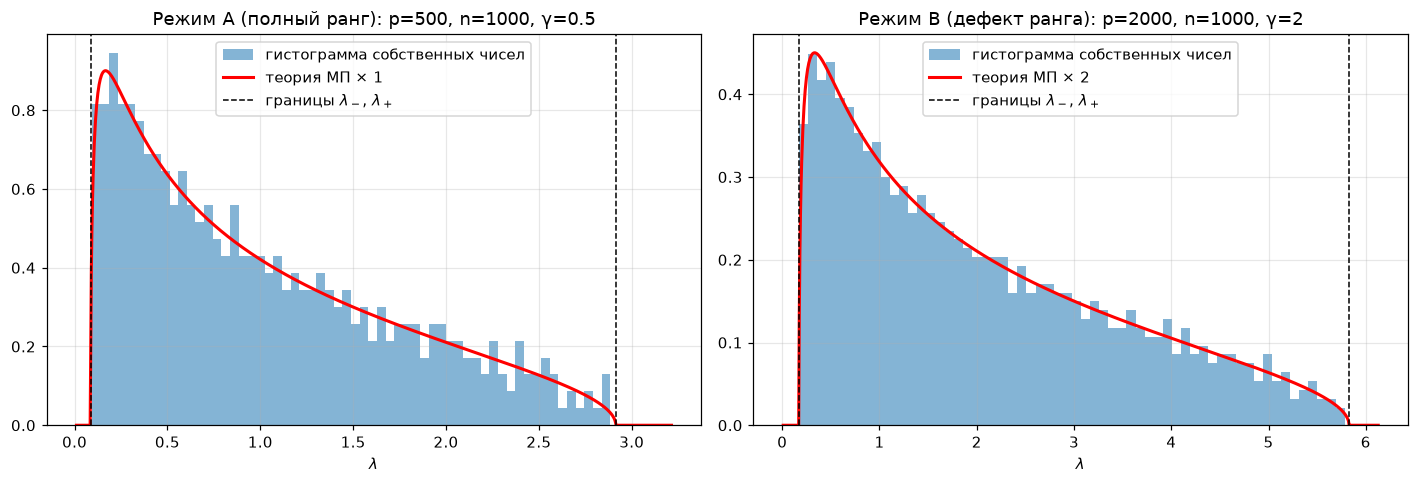

In [3]:
n = 1000
regimes = {"A (полный ранг)": 500, "B (дефект ранга)": 2000}
table_rows = []

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (regime_name, p) in zip(axes, regimes.items()):
    gamma = p / n
    eigenvalues = noise_eigenvalues(p, n)

    zero_tol = 1e-10 * eigenvalues.max()
    nonzero = eigenvalues[eigenvalues > zero_tol]
    n_zeros = len(eigenvalues) - len(nonzero)

    lam_minus, lam_plus = mp_bounds(gamma)
    scale = gamma if gamma > 1 else 1.0

    lam_grid = np.linspace(0.01, lam_plus + 0.3, 1000)
    ax.hist(nonzero, bins=60, density=True, alpha=0.55, label="гистограмма собственных чисел")
    ax.plot(lam_grid, scale * mp_density(lam_grid, gamma), "r", lw=2, label=f"теория МП × {scale:g}")
    ax.axvline(lam_minus, color="k", ls="--", lw=1, label=r"границы $\lambda_-$, $\lambda_+$")
    ax.axvline(lam_plus, color="k", ls="--", lw=1)
    ax.set_title(f"Режим {regime_name}: p={p}, n={n}, γ={gamma:g}")
    ax.set_xlabel(r"$\lambda$")
    ax.legend()

    table_rows.append((regime_name, gamma, lam_minus, nonzero.min(), lam_plus, nonzero.max(), n_zeros))
    if n_zeros > 0:
        zeros = eigenvalues[eigenvalues <= zero_tol]
        print(f"{regime_name}: нулевых собственных чисел {n_zeros} (ожидалось p - n = {p - n}); "
              f"самый большой |ноль| = {np.abs(zeros).max():.1e}; отрицательных среди них: {(zeros < 0).sum()}")
plt.tight_layout()
plt.show()

In [4]:
print(f"{'Режим':<18}{'γ':>4}{'λ- теор':>10}{'λmin эксп':>11}{'λ+ теор':>10}{'λmax эксп':>11}{'нулей':>7}")
for regime_name, gamma, lam_minus, lam_min_exp, lam_plus, lam_max_exp, n_zeros in table_rows:
    print(f"{regime_name:<18}{gamma:>4g}{lam_minus:>10.4f}{lam_min_exp:>11.4f}"
          f"{lam_plus:>10.4f}{lam_max_exp:>11.4f}{n_zeros:>7}")

Режим                γ   λ- теор  λmin эксп   λ+ теор  λmax эксп  нулей
A (полный ранг)    0.5    0.0858     0.0928    2.9142     2.8841      0
B (дефект ранга)     2    0.1716     0.1734    5.8284     5.7837   1000


### 1.3. Как «гуляет» самое большое собственное число (случай $p = n$, $\gamma = 1$)

In [5]:
def largest_noise_eigenvalue(p, n):
    X = random_gen.standard_normal((p, n))
    largest_singular_value = svds(X, k=1, return_singular_vectors=False)[0]
    return largest_singular_value ** 2 / n


sizes = [100, 200, 400, 800, 1600]
n_repeats = 40

print("Прогноз Трейси–Видома: n^(2/3)·(среднее - 4) ≈ -3.04,  n^(2/3)·std ≈ 3.20\n")
print(f"{'n = p':>6}{'среднее λmax':>14}{'std':>8}{'n^(2/3)·(среднее-4)':>21}{'n^(2/3)·std':>13}{'доля λmax > 4':>15}")
for size in sizes:
    lam_max_samples = np.array([largest_noise_eigenvalue(size, size) for _ in range(n_repeats)])
    scale = size ** (2 / 3)
    print(f"{size:>6}{lam_max_samples.mean():>14.4f}{lam_max_samples.std():>8.4f}"
          f"{scale * (lam_max_samples.mean() - 4):>21.2f}{scale * lam_max_samples.std():>13.2f}"
          f"{(lam_max_samples > 4).mean():>15.2f}")

Прогноз Трейси–Видома: n^(2/3)·(среднее - 4) ≈ -3.04,  n^(2/3)·std ≈ 3.20

 n = p  среднее λmax     std  n^(2/3)·(среднее-4)  n^(2/3)·std  доля λmax > 4
   100        3.8259  0.1524                -3.75         3.28           0.12


   200        3.8955  0.0877                -3.58         3.00           0.07


   400        3.9249  0.0517                -4.08         2.81           0.05


   800        3.9639  0.0379                -3.11         3.26           0.15


  1600        3.9813  0.0224                -2.55         3.07           0.23


## Задание 2. Фазовый переход BBP: когда PCA видит сигнал
### 2.1. Генерация данных

In [6]:
n_features = 1500
n_samples = 3000
gamma2 = n_features / n_samples
theta_c = np.sqrt(gamma2)
lam_minus2, lam_plus2 = mp_bounds(gamma2)
print(f"γ = {gamma2}, θc = {theta_c:.4f}, λ- = {lam_minus2:.4f}, λ+ = {lam_plus2:.4f}")


def make_spiked_data(theta):
    Y = random_gen.standard_normal((n_features, n_samples))
    Y[0] *= np.sqrt(1 + theta)
    return Y


def top_eigenpair(Y):
    U, S, _ = svds(Y / np.sqrt(Y.shape[1]), k=1)
    return S[0] ** 2, U[:, 0]

γ = 0.5, θc = 0.7071, λ- = 0.0858, λ+ = 2.9142


### 2.2. Ловушка с порядком собственных чисел

In [7]:
Y = make_spiked_data(theta=2.0)

start = time.perf_counter()
all_eigenvalues, all_eigenvectors = np.linalg.eigh(Y @ Y.T / n_samples)
time_eigh = time.perf_counter() - start

start = time.perf_counter()
lam1, v1_hat = top_eigenpair(Y)
time_svds = time.perf_counter() - start

print(f"eigh, элемент [0]  (ошибка): λ = {all_eigenvalues[0]:.4f}, <v,e1>² = {all_eigenvectors[0, 0] ** 2:.2e}  <- это λ_min!")
print(f"eigh, элемент [-1] (верно):  λ = {all_eigenvalues[-1]:.4f}, <v,e1>² = {all_eigenvectors[0, -1] ** 2:.4f}")
print(f"svds, k=1:                   λ = {lam1:.4f}, <v,e1>² = {v1_hat[0] ** 2:.4f}")
print(f"Время: eigh {time_eigh:.2f} c, svds {time_svds:.2f} c")

eigh, элемент [0]  (ошибка): λ = 0.0864, <v,e1>² = 6.42e-05  <- это λ_min!
eigh, элемент [-1] (верно):  λ = 3.7107, <v,e1>² = 0.7053
svds, k=1:                   λ = 3.7107, <v,e1>² = 0.7053
Время: eigh 0.44 c, svds 0.13 c


### 2.3. Перебор силы сигнала $\theta$ от 0.1 до 2.5, по 10 генераций на каждое значение

In [8]:
def bbp_lambda_theory(theta, gamma):
    if theta <= np.sqrt(gamma):
        return (1 + np.sqrt(gamma)) ** 2
    return (1 + theta) * (1 + gamma / theta)


def bbp_overlap_theory(theta, gamma):
    if theta <= np.sqrt(gamma):
        return 0.0
    return (1 - gamma / theta ** 2) / (1 + gamma / theta)


thetas = np.round(np.arange(0.1, 2.51, 0.1), 1)
n_runs = 10
lam1_results = np.zeros((len(thetas), n_runs))
overlap_results = np.zeros((len(thetas), n_runs))

start = time.perf_counter()
for i, theta in enumerate(thetas):
    for run in range(n_runs):
        lam1, v1_hat = top_eigenpair(make_spiked_data(theta))
        lam1_results[i, run] = lam1
        overlap_results[i, run] = v1_hat[0] ** 2
print(f"Готово за {time.perf_counter() - start:.0f} c")

Готово за 76 c


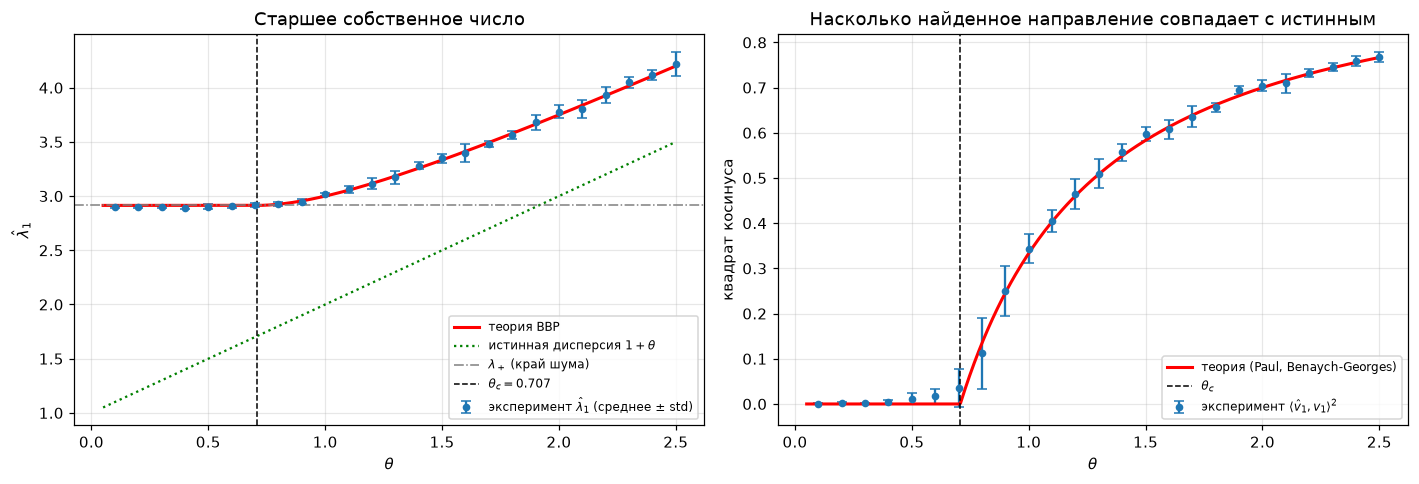

In [9]:
theta_grid = np.linspace(0.05, 2.5, 500)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.errorbar(thetas, lam1_results.mean(axis=1), yerr=lam1_results.std(axis=1), fmt="o", ms=4, capsize=3,
            label=r"эксперимент $\hat\lambda_1$ (среднее ± std)")
ax.plot(theta_grid, [bbp_lambda_theory(t, gamma2) for t in theta_grid], "r", lw=2, label="теория BBP")
ax.plot(theta_grid, 1 + theta_grid, "g:", lw=1.5, label=r"истинная дисперсия $1+\theta$")
ax.axhline(lam_plus2, color="gray", ls="-.", lw=1, label=r"$\lambda_+$ (край шума)")
ax.axvline(theta_c, color="k", ls="--", lw=1, label=rf"$\theta_c={theta_c:.3f}$")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel(r"$\hat\lambda_1$")
ax.set_title("Старшее собственное число")
ax.legend(fontsize=8)

ax = axes[1]
ax.errorbar(thetas, overlap_results.mean(axis=1), yerr=overlap_results.std(axis=1), fmt="o", ms=4, capsize=3,
            label=r"эксперимент $\langle\hat v_1,v_1\rangle^2$")
ax.plot(theta_grid, [bbp_overlap_theory(t, gamma2) for t in theta_grid], "r", lw=2,
        label="теория (Paul, Benaych-Georges)")
ax.axvline(theta_c, color="k", ls="--", lw=1, label=r"$\theta_c$")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("квадрат косинуса")
ax.set_title("Насколько найденное направление совпадает с истинным")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 2.4. Калибровка: восстанавливаем истинную силу сигнала

In [10]:
TW_QUANTILE_99 = 2.02
NO_SIGNAL = "Сигнал отсутствует или находится ниже предела детектирования"


def detection_threshold(p, n):
    sigma_tw = (np.sqrt(n) + np.sqrt(p)) * (1 / np.sqrt(n) + 1 / np.sqrt(p)) ** (1 / 3) / n
    return (1 + np.sqrt(p / n)) ** 2 + TW_QUANTILE_99 * sigma_tw


def calibrate_theta(lam1, p=n_features, n=n_samples):
    if lam1 <= detection_threshold(p, n):
        return NO_SIGNAL
    gamma = p / n
    b = lam1 + 1 - gamma
    return (b + np.sqrt(b ** 2 - 4 * lam1)) / 2 - 1


print(f"Порог детектирования: λ̂1 > {detection_threshold(n_features, n_samples):.4f}  (λ+ = {lam_plus2:.4f})\n")
for lam1 in [2.9, 2.95, 3.0, 3.75, 5.0]:
    result = calibrate_theta(lam1)
    print(f"λ̂1 = {lam1:<5} ->", result if result == NO_SIGNAL else f"θ̂ = {result:.4f}")

Порог детектирования: λ̂1 > 2.9365  (λ+ = 2.9142)

λ̂1 = 2.9   -> Сигнал отсутствует или находится ниже предела детектирования
λ̂1 = 2.95  -> θ̂ = 0.8851
λ̂1 = 3.0   -> θ̂ = 1.0000
λ̂1 = 3.75  -> θ̂ = 2.0000
λ̂1 = 5.0   -> θ̂ = 3.3508


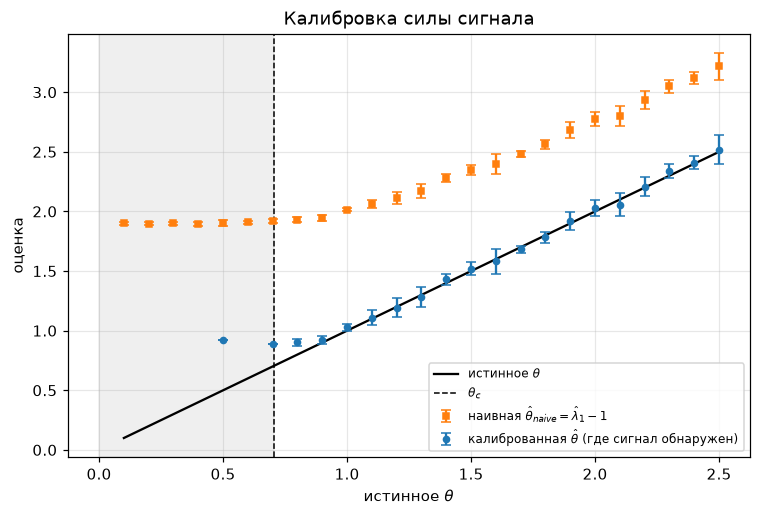

    θ   наивная   калибр.   обнаружен
  0.1     1.900       nan        0/10
  0.2     1.898       nan        0/10
  0.3     1.901       nan        0/10
  0.4     1.894       nan        0/10
  0.5     1.903     0.919        1/10
  0.6     1.907       nan        0/10
  0.7     1.919     0.888        2/10
  0.8     1.931     0.901        3/10
  0.9     1.947     0.921        6/10
  1.0     2.015     1.029       10/10
  1.1     2.062     1.110       10/10
  1.2     2.115     1.194       10/10
  1.3     2.173     1.281       10/10
  1.4     2.282     1.432       10/10
  1.5     2.350     1.521       10/10
  1.6     2.400     1.583       10/10
  1.7     2.481     1.684       10/10
  1.8     2.563     1.782       10/10
  1.9     2.680     1.919       10/10
  2.0     2.778     2.032       10/10
  2.1     2.801     2.057       10/10
  2.2     2.935     2.208       10/10
  2.3     3.050     2.335       10/10
  2.4     3.117     2.410       10/10
  2.5     3.217     2.518       10/10


In [11]:
theta_naive = lam1_results - 1
theta_calibrated = np.full(lam1_results.shape, np.nan)
for i in range(len(thetas)):
    for run in range(n_runs):
        result = calibrate_theta(lam1_results[i, run])
        if result != NO_SIGNAL:
            theta_calibrated[i, run] = result

calibrated_mean = np.full(len(thetas), np.nan)
calibrated_std = np.full(len(thetas), np.nan)
n_detected = np.zeros(len(thetas), dtype=int)
for i, row in enumerate(theta_calibrated):
    found = row[~np.isnan(row)]
    n_detected[i] = len(found)
    if len(found) > 0:
        calibrated_mean[i], calibrated_std[i] = found.mean(), found.std()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(thetas, thetas, "k-", lw=1.5, label=r"истинное $\theta$")
ax.errorbar(thetas, theta_naive.mean(axis=1), yerr=theta_naive.std(axis=1), fmt="s", ms=4, capsize=3,
            color="tab:orange", label=r"наивная $\hat\theta_{naive}=\hat\lambda_1-1$")
ax.errorbar(thetas, calibrated_mean, yerr=calibrated_std, fmt="o", ms=4, capsize=3,
            color="tab:blue", label=r"калиброванная $\hat\theta$ (где сигнал обнаружен)")
ax.axvline(theta_c, color="k", ls="--", lw=1, label=r"$\theta_c$")
ax.axvspan(0, theta_c, color="gray", alpha=0.12)
ax.set_xlabel(r"истинное $\theta$")
ax.set_ylabel("оценка")
ax.set_title("Калибровка силы сигнала")
ax.legend(fontsize=8)
plt.show()

print(f"{'θ':>5}{'наивная':>10}{'калибр.':>10}{'обнаружен':>12}")
for theta, naive, calibrated, detected in zip(thetas, theta_naive.mean(axis=1), calibrated_mean, n_detected):
    print(f"{theta:>5.1f}{naive:>10.3f}{calibrated:>10.3f}{detected:>9}/{n_runs}")

## Задание 3. Диагностика слоёв ResNet-18 по спектру весов (теория Мартина–Махони)
### 3.1. Матрица слоя и её спектр

In [12]:
import torch
import torchvision.models as models

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.eval()
model_weights = dict(model.named_parameters())


def layer_matrix(layer_name):
    W = model_weights[layer_name + ".weight"].detach().double().numpy()
    return W.reshape(W.shape[0], -1)


def layer_eigenvalues(W):
    N = max(W.shape)
    singular_values = np.linalg.svd(W, compute_uv=False)
    eigenvalues = singular_values ** 2 / N
    eigenvalues = eigenvalues[eigenvalues > 1e-10 * eigenvalues.max()]
    return np.sort(eigenvalues)


W = layer_matrix("layer4.1.conv2")

start = time.perf_counter()
eigenvalues_fast = layer_eigenvalues(W)
time_fast = time.perf_counter() - start

start = time.perf_counter()
eigenvalues_full = np.linalg.eigvalsh(W.T @ W / max(W.shape))
time_full = time.perf_counter() - start

print(f"layer4.1.conv2: W {W.shape}, ненулевых собственных чисел: {len(eigenvalues_fast)}")
print(f"через SVD: {time_fast:.2f} c;  полная матрица 4608x4608: {time_full:.2f} c, "
      f"из них почти нулевых: {(np.abs(eigenvalues_full) < 1e-10).sum()}")
print("максимальное расхождение 512 старших чисел:",
      np.abs(eigenvalues_full[-len(eigenvalues_fast):] - eigenvalues_fast).max())

layer4.1.conv2: W (512, 4608), ненулевых собственных чисел: 512
через SVD: 0.43 c;  полная матрица 4608x4608: 5.94 c, из них почти нулевых: 4096
максимальное расхождение 512 старших чисел: 5.095750210681871e-18


### 3.2. Подгонка степенного закона для `layer4.1.conv2`
#### Наивный способ: МНК по гистограмме

 бинов   α (линейные бины)   α (лог. бины)
    10               2.205           1.287
    20               1.692           1.374
    30               1.408           1.246
    50               1.286           1.169
    80               1.095           1.079
   120               1.019           0.991
   200               0.881           0.945


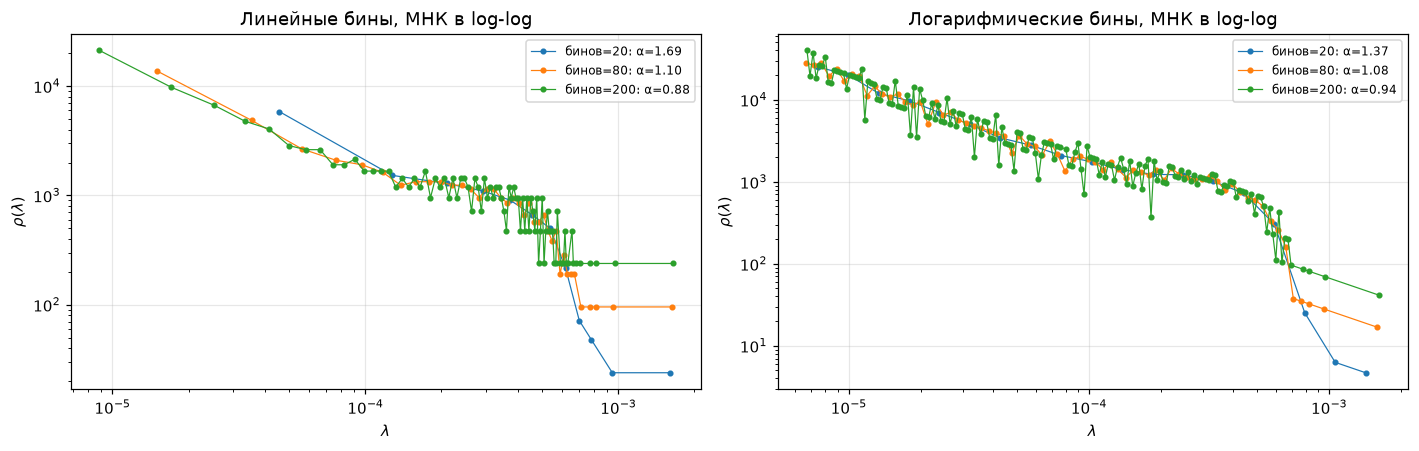

In [13]:
def ols_alpha(eigenvalues, n_bins, log_bins=False):
    if log_bins:
        edges = np.geomspace(eigenvalues.min(), eigenvalues.max(), n_bins + 1)
        centers = np.sqrt(edges[:-1] * edges[1:])
    else:
        edges = np.linspace(eigenvalues.min(), eigenvalues.max(), n_bins + 1)
        centers = (edges[:-1] + edges[1:]) / 2
    counts, _ = np.histogram(eigenvalues, bins=edges)
    density = counts / (counts.sum() * np.diff(edges))
    use = (np.arange(n_bins) >= np.argmax(density)) & (counts > 0)
    slope, _ = np.polyfit(np.log(centers[use]), np.log(density[use]), 1)
    return -slope, centers[use], density[use]


print(f"{'бинов':>6}{'α (линейные бины)':>20}{'α (лог. бины)':>16}")
for n_bins in [10, 20, 30, 50, 80, 120, 200]:
    alpha_linear = ols_alpha(eigenvalues_fast, n_bins)[0]
    alpha_log = ols_alpha(eigenvalues_fast, n_bins, log_bins=True)[0]
    print(f"{n_bins:>6}{alpha_linear:>20.3f}{alpha_log:>16.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, log_bins in zip(axes, [False, True]):
    for n_bins in [20, 80, 200]:
        alpha, centers, density = ols_alpha(eigenvalues_fast, n_bins, log_bins)
        ax.loglog(centers, density, "o-", ms=3, lw=0.8, label=f"бинов={n_bins}: α={alpha:.2f}")
    ax.set_title(("Логарифмические" if log_bins else "Линейные") + " бины, МНК в log-log")
    ax.set_xlabel(r"$\lambda$")
    ax.set_ylabel(r"$\rho(\lambda)$")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

#### Правильный способ: MLE (оценка Хилла) + выбор $\lambda_{\min}$ по Колмогорову–Смирнову

In [14]:
def hill_alpha(tail, lam_min):
    return 1 + len(tail) / np.sum(np.log(tail / lam_min))


def fit_power_law(eigenvalues, min_tail_size=10):
    eigenvalues = np.sort(eigenvalues)
    if len(eigenvalues) <= min_tail_size:
        return None
    best_fit = None
    for start in range(len(eigenvalues) - min_tail_size + 1):
        lam_min = eigenvalues[start]
        tail = eigenvalues[start:]
        alpha = hill_alpha(tail, lam_min)
        theory_cdf = 1 - (tail / lam_min) ** (-(alpha - 1))
        k = len(tail)
        cdf_after_step = np.arange(1, k + 1) / k
        cdf_before_step = np.arange(k) / k
        ks_distance = max(np.max(cdf_after_step - theory_cdf), np.max(theory_cdf - cdf_before_step))
        if best_fit is None or ks_distance < best_fit["ks_distance"]:
            best_fit = {"alpha": alpha, "lam_min": lam_min, "ks_distance": ks_distance, "tail_size": len(tail)}
    return best_fit


fit = fit_power_law(eigenvalues_fast)
print(f"layer4.1.conv2: α = {fit['alpha']:.3f}, λ_min = {fit['lam_min']:.3e}, D_KS = {fit['ks_distance']:.3f}, "
      f"точек в хвосте: {fit['tail_size']} из {len(eigenvalues_fast)}")

print("\nДля сравнения — α при λ_min, выбранном «на глаз» (квантиль спектра):")
for quantile in [0.5, 0.7, 0.8, 0.9]:
    lam_min = np.quantile(eigenvalues_fast, quantile)
    tail = eigenvalues_fast[eigenvalues_fast >= lam_min]
    print(f"  λ_min = квантиль {quantile}: α = {hill_alpha(tail, lam_min):.3f}")

layer4.1.conv2: α = 5.828, λ_min = 4.740e-04, D_KS = 0.064, точек в хвосте: 44 из 512

Для сравнения — α при λ_min, выбранном «на глаз» (квантиль спектра):
  λ_min = квантиль 0.5: α = 1.964
  λ_min = квантиль 0.7: α = 3.067
  λ_min = квантиль 0.8: α = 3.981
  λ_min = квантиль 0.9: α = 5.469


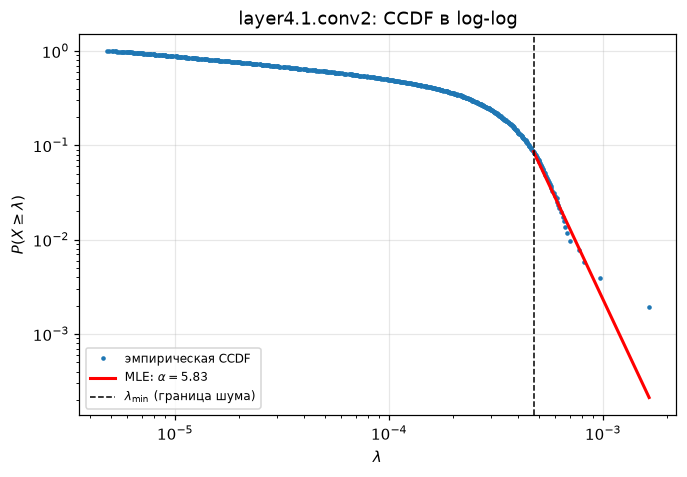

In [15]:
def plot_ccdf(ax, eigenvalues, fit, title):
    eigenvalues = np.sort(eigenvalues)
    ccdf = 1 - np.arange(len(eigenvalues)) / len(eigenvalues)
    ax.loglog(eigenvalues, ccdf, ".", ms=4, label="эмпирическая CCDF")
    if fit is not None:
        x = np.geomspace(fit["lam_min"], eigenvalues.max(), 100)
        tail_share = fit["tail_size"] / len(eigenvalues)
        ax.loglog(x, tail_share * (x / fit["lam_min"]) ** (-(fit["alpha"] - 1)), "r-", lw=2,
                  label=rf"MLE: $\alpha={fit['alpha']:.2f}$")
        ax.axvline(fit["lam_min"], color="k", ls="--", lw=1, label=r"$\lambda_{\min}$ (граница шума)")
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlabel(r"$\lambda$")
    ax.set_ylabel(r"$P(X\geq\lambda)$")
    ax.set_title(title)
    ax.legend(fontsize=8)


fig, ax = plt.subplots(figsize=(7, 4.5))
plot_ccdf(ax, eigenvalues_fast, fit, "layer4.1.conv2: CCDF в log-log")
plt.show()

### 3.3. Слепой тест: 4 слоя с разными «болезнями»

In [16]:
def keep_top_singular_values(W, k):
    U, S, Vt = np.linalg.svd(W, full_matrices=False)
    S[k:] = 0.0
    return U @ np.diag(S) @ Vt


original_layer1 = layer_matrix("layer1.0.conv1")
test_layers = {
    "layer1.0.conv1": ("случайный", random_gen.normal(0.0, original_layer1.std(), size=original_layer1.shape)),
    "layer2.0.conv1": ("штатный", layer_matrix("layer2.0.conv1")),
    "layer3.0.conv1": ("коллапс", keep_top_singular_values(layer_matrix("layer3.0.conv1"), k=2)),
    "fc": ("выходной", layer_matrix("fc")),
}

with torch.no_grad():
    for layer_name, (_, W) in test_layers.items():
        weight = model_weights[layer_name + ".weight"]
        weight.copy_(torch.from_numpy(W).reshape(weight.shape))

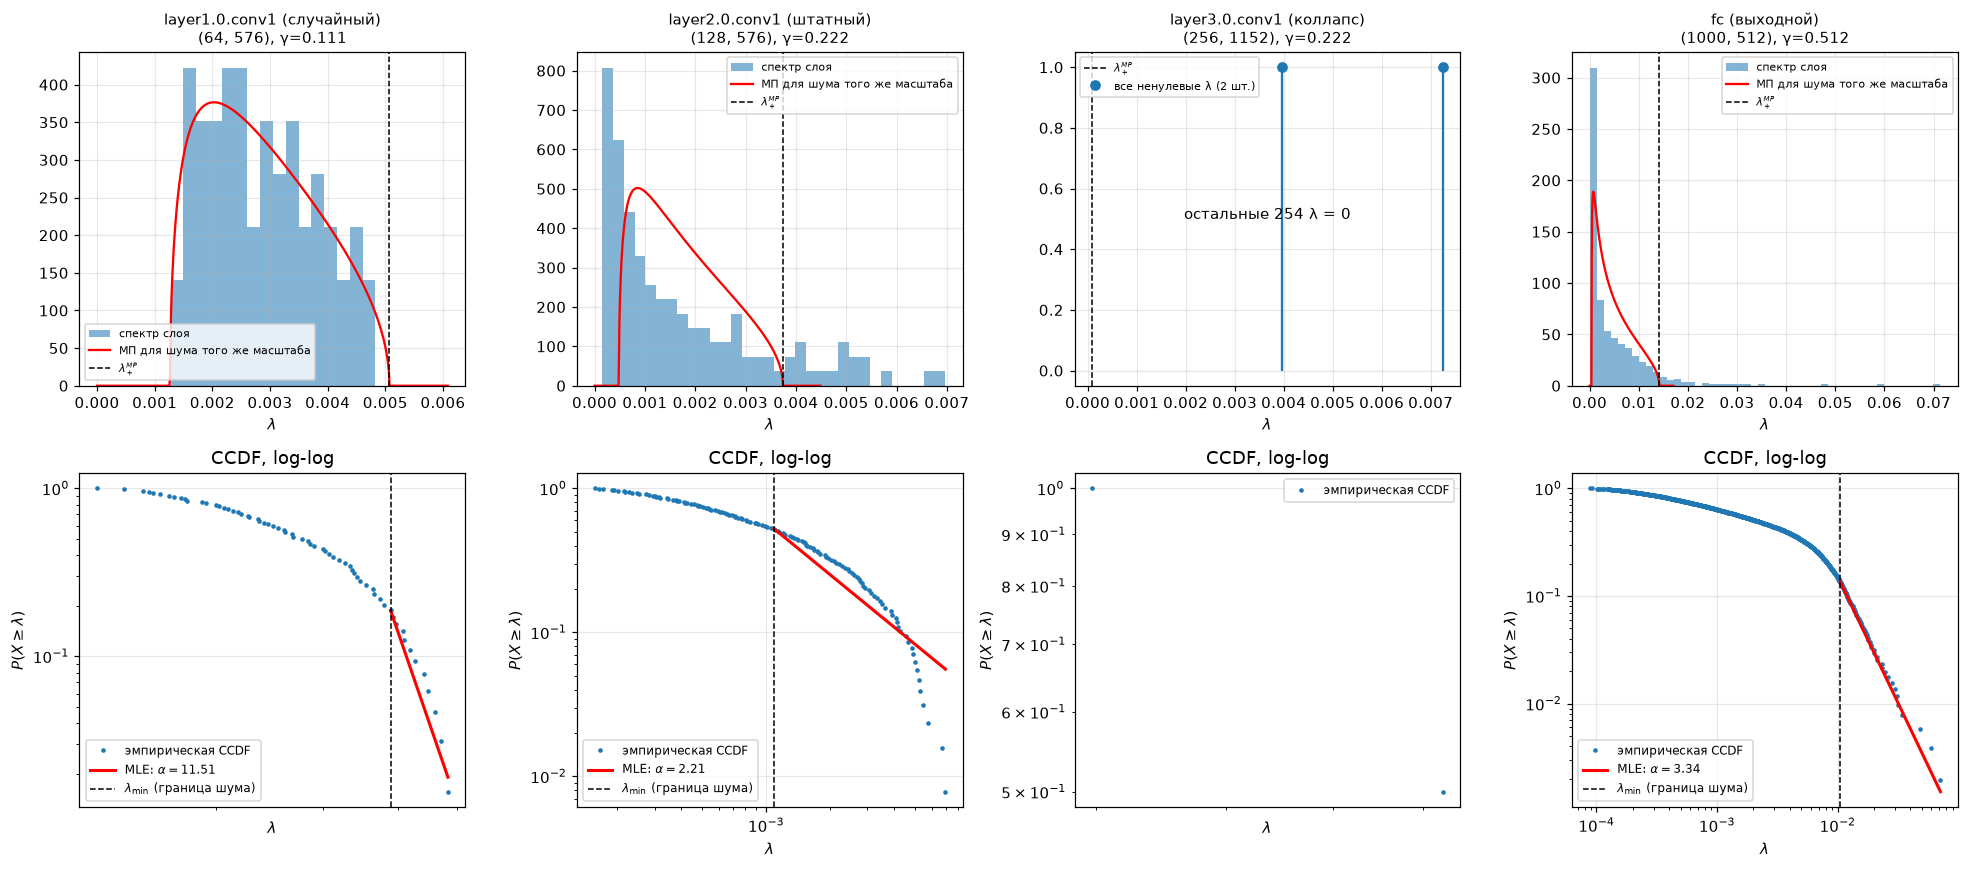

In [17]:
def stable_rank(eigenvalues):
    return eigenvalues.sum() / eigenvalues.max()


summary = []
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for column, (layer_name, (label, W)) in enumerate(test_layers.items()):
    eigenvalues = layer_eigenvalues(W)
    gamma = min(W.shape) / max(W.shape)
    lam_minus, lam_plus = mp_bounds(gamma, sigma2=W.var())
    fit = fit_power_law(eigenvalues)
    summary.append({
        "name": f"{layer_name} ({label})", "shape": W.shape, "n_eigenvalues": len(eigenvalues),
        "srank": stable_rank(eigenvalues), "alpha": fit["alpha"] if fit else None,
        "lam_max": eigenvalues.max(), "lam_plus": lam_plus, "n_above_mp": int((eigenvalues > lam_plus).sum()),
    })

    ax = axes[0, column]
    if len(eigenvalues) > 10:
        ax.hist(eigenvalues, bins=min(50, len(eigenvalues) // 4), density=True, alpha=0.55, label="спектр слоя")
        lam_grid = np.linspace(1e-12, 1.2 * lam_plus, 500)
        ax.plot(lam_grid, mp_density(lam_grid, gamma, W.var()), "r", lw=1.5, label="МП для шума того же масштаба")
    else:
        ax.stem(eigenvalues, np.ones_like(eigenvalues), basefmt=" ", label=f"все ненулевые λ ({len(eigenvalues)} шт.)")
        ax.text(0.5, 0.5, f"остальные {min(W.shape) - len(eigenvalues)} λ = 0", transform=ax.transAxes, ha="center")
    ax.axvline(lam_plus, color="k", ls="--", lw=1, label=r"$\lambda_+^{MP}$")
    ax.set_title(f"{layer_name} ({label})\n{W.shape}, γ={gamma:.3f}", fontsize=10)
    ax.set_xlabel(r"$\lambda$")
    ax.legend(fontsize=7)

    plot_ccdf(axes[1, column], eigenvalues, fit, "CCDF, log-log")
plt.tight_layout()
plt.show()

In [18]:
print(f"{'слой':<26}{'форма':>13}{'#λ':>5}{'srank':>8}{'α (MLE)':>9}{'λmax':>11}{'λ+ МП':>11}{'#λ > λ+':>9}")
for row in summary:
    alpha = "нет" if row["alpha"] is None else f"{row['alpha']:.2f}"
    print(f"{row['name']:<26}{str(row['shape']):>13}{row['n_eigenvalues']:>5}{row['srank']:>8.2f}{alpha:>9}"
          f"{row['lam_max']:>11.2e}{row['lam_plus']:>11.2e}{row['n_above_mp']:>9}")

слой                              форма   #λ   srank  α (MLE)       λmax      λ+ МП  #λ > λ+
layer1.0.conv1 (случайный)    (64, 576)   64   37.82    11.51   4.83e-03   5.07e-03        0
layer2.0.conv1 (штатный)     (128, 576)  128   31.78     2.21   6.97e-03   3.74e-03       18
layer3.0.conv1 (коллапс)    (256, 1152)    2    1.55      нет   7.25e-03   9.10e-05        2
fc (выходной)               (1000, 512)  512   34.60     3.34   7.14e-02   1.42e-02       35
